# AI skills in job ads

**How often do Gulf job ads ask for AI, in which sectors, for what kind of AI work, and how does the region compare with the rest of the world?**

This notebook rebuilds the processed tables from `data/raw/readings.csv`, recomputes the headline figures and checks that they match the build script output.

In [1]:
import os, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
import build_data
tidy = build_data.build()

                       figure  value
          gulf_share_2022_pct  1.200
        gulf_share_2026h1_pct  3.400
         gulf_growth_multiple  2.830
               role_build_pct  9.000
    role_use_or_implement_pct 66.000
        uae_ai_index_2025_pct  2.870
      uae_ai_index_rank_of_22  7.000
     median_22_areas_2025_pct  1.855
             uae_pwc_2021_pct  1.000
             uae_pwc_2025_pct  3.200
uae_ai_postings_2021_thousand  4.600
uae_ai_postings_2025_thousand 12.200

104 figures, 37 in two or more documents


## 1. Data checks
Row counts, missing values and coverage of the raw readings.

In [2]:
raw = pd.read_csv(ROOT / 'data/raw/readings.csv', dtype=str).fillna('')
print('raw readings:', len(raw), '| documents:', raw.source_id.nunique())
print('set aside:', raw.note.str.startswith('set_aside').sum())
print(tidy.groupby(['dataset', 'verification']).size().unstack(fill_value=0))
print('missing values in tidy value column:', tidy.value.isna().sum())

raw readings: 291 | documents: 16
set aside: 4
verification        one-document  two-or-more-documents
dataset                                                
ai_index_lightcast            44                      8
gulftalent                    11                     26
pwc_lightcast                 12                      3
missing values in tidy value column: 0


## 2. Gulf: share of vacancies mentioning AI, 2022 and H1 2026

In [3]:
trend = pd.read_csv(ROOT / 'data/processed/ai_share_trend.csv')
g = trend[trend.source == 'GulfTalent'].set_index('period').share_pct
mult = g['2026H1'] / g['2022']
print(trend.to_string(index=False))
print(f'Gulf multiple 2022 to H1 2026: {mult:.2f}x')

                                                        series                     source period  share_pct          verification
GulfTalent: professional vacancies, UAE + Saudi Arabia + Qatar                 GulfTalent   2022        1.2 two-or-more-documents
GulfTalent: professional vacancies, UAE + Saudi Arabia + Qatar                 GulfTalent 2026H1        3.4 two-or-more-documents
             PwC/Lightcast: all postings, United Arab Emirates PwC AI Jobs Barometer 2026   2021        1.0 two-or-more-documents
             PwC/Lightcast: all postings, United Arab Emirates PwC AI Jobs Barometer 2026   2025        3.2 two-or-more-documents
       PwC/Lightcast: all postings, World (27-country average) PwC AI Jobs Barometer 2026   2021        1.8          one-document
       PwC/Lightcast: all postings, World (27-country average) PwC AI Jobs Barometer 2026   2025        3.2          one-document
                            PwC/Lightcast: all postings, India PwC AI Jobs Barometer 2026 

## 3. What AI-linked Gulf vacancies ask the worker to do

                            role  share_of_ai_vacancies_pct  n_sources
                 Implementing AI                       35.0          2
             Using AI in the job                       31.0          2
Selling AI products and services                       25.0          2
 Building and training AI models                        9.0          2
build: 9.0 | use or implement: 66.0


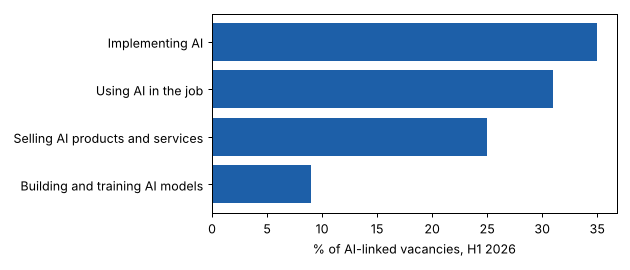

In [4]:
roles = pd.read_csv(ROOT / 'data/processed/gulf_ai_vacancies_by_role.csv')
print(roles.to_string(index=False))
build_share = roles.set_index('role').loc['Building and training AI models', 'share_of_ai_vacancies_pct']
use_impl = roles.set_index('role').loc[['Implementing AI', 'Using AI in the job'], 'share_of_ai_vacancies_pct'].sum()
print('build:', build_share, '| use or implement:', use_impl)
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(roles.role[::-1], roles.share_of_ai_vacancies_pct[::-1], color='#1d5fa8')
ax.set_xlabel('% of AI-linked vacancies, H1 2026')
plt.tight_layout(); plt.show()

## 4. Gulf sectors (published ratios)

In [5]:
sec = pd.read_csv(ROOT / 'data/processed/gulf_ai_share_by_sector.csv')
print(sec.to_string(index=False))

       sector   published_ratio  ratio_pct  exact_pct  exact_is_upper_bound  ratio_sources  exact_sources
   Technology            1 in 3      33.33       31.6                 False              9              1
      Banking           1 in 15       6.67        8.1                 False              9              1
        Audit           1 in 15       6.67        5.8                 False              9              1
  Oil and gas           1 in 30       3.33        3.6                 False              8              1
  Real estate           1 in 30       3.33        2.6                 False              8              1
 Construction 1 in 100 or fewer       1.00        NaN                  True              7              1
       Retail 1 in 100 or fewer       1.00        NaN                  True              7              1
   Healthcare 1 in 100 or fewer       1.00        NaN                  True              7              1
Manufacturing 1 in 100 or fewer       1.00    

## 5. AI job postings by economy, 2025 (AI Index 2026), Middle East first

In [6]:
c = pd.read_csv(ROOT / 'data/processed/ai_share_by_country_2025.csv')
print(c.to_string(index=False))
uae = c.set_index('country').loc['United Arab Emirates']
median = c.ai_share_pct_2025.median()
print(f"UAE {uae.ai_share_pct_2025}% rank {uae['rank']} of {len(c)}; median {median:.3f}%")
print(c.groupby('region').ai_share_pct_2025.agg(['count', 'mean', 'min', 'max']).round(2))

     region              country  ai_share_pct_2025  rank  n_sources          verification
Middle East United Arab Emirates               2.87     7          3 two-or-more-documents
       Asia            Singapore               4.69     1          2 two-or-more-documents
       Asia            Hong Kong               3.48     2          2 two-or-more-documents
     Europe           Luxembourg               3.43     3          2 two-or-more-documents
     Europe                Spain               3.31     4          2 two-or-more-documents
     Europe               Poland               2.92     6          1          one-document
     Europe               Sweden               2.77     8          1          one-document
     Europe       United Kingdom               1.93    11          2 two-or-more-documents
     Europe          Switzerland               1.59    13          1          one-document
     Europe              Belgium               1.36    15          1          one-document

## 6. United States by sector, 2024 and 2025

In [7]:
us = pd.read_csv(ROOT / 'data/processed/us_ai_share_by_sector.csv')
print(us.to_string(index=False))
print('sectors that rose:', (us.change_pts > 0).sum(), 'of', len(us))

                                              sector  share_2024_pct  share_2025_pct  change_pts
                                         Information            7.82           13.22        5.40
    Professional, scientific, and technical services            4.41            6.49        2.08
                               Finance and insurance            3.27            5.33        2.06
                                       Manufacturing            3.35            4.66        1.31
             Management of companies and enterprises            1.62            3.28        1.66
                                           Utilities            2.00            2.89        0.89
                                Educational services            2.03            2.42        0.39
                  Real estate and rental and leasing            1.08            2.08        1.00
                                     Wholesale trade            1.06            1.93        0.87
       Mining, quarrying, and 

## 7. Recompute headline figures and compare with the build script output

In [8]:
head = pd.read_csv(ROOT / 'data/processed/headline_figures.csv').set_index('figure').value
mine = {
  'gulf_share_2022_pct': g['2022'], 'gulf_share_2026h1_pct': g['2026H1'], 'gulf_growth_multiple': round(mult, 2),
  'role_build_pct': build_share, 'role_use_or_implement_pct': use_impl,
  'uae_ai_index_2025_pct': uae.ai_share_pct_2025, 'uae_ai_index_rank_of_22': uae['rank'],
  'median_22_areas_2025_pct': round(median, 3),
}
for k, val in mine.items():
    assert abs(float(val) - head[k]) < 1e-9, (k, val, head[k])
print('all', len(mine), 'headline figures match the build script output')

all 8 headline figures match the build script output
